In [20]:
with open('the-verdict.txt',mode='r',encoding='utf-8') as f:
  raw_text = f.read()



In [21]:
raw_text

'I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.)\n\n"The height of his glory"--that was what the women called it. I can hear Mrs. Gideon Thwing--his last Chicago sitter--deploring his unaccountable abdication. "Of course it\'s going to send the value of my picture \'way up; but I don\'t think of that, Mr. Rickham--the loss to Arrt is all I think of." The word, on Mrs. Thwing\'s lips, multiplied its _rs_ as though they were reflected in an endless vista of mirrors. And it was not only the Mrs. Thwings who mourned. Had not the exquisite Hermia Croft, at the last Grafton Gallery show, stopped me before Gisburn\'s "Moon-dancers" to say, with tears in her eyes: "We shall not look upon its like again"?\n\nWell!--even 

In [22]:
print("Total number of characters",len(raw_text))
print("Total number of words",len(raw_text.split()))
print("Total number of lines",len(raw_text.split('\n')))

Total number of characters 20479
Total number of words 3634
Total number of lines 165


In [23]:
import re

text = "Hello darling, long time no see."
result = re.split(r'(\s)',text)

print(result)

['Hello', ' ', 'darling,', ' ', 'long', ' ', 'time', ' ', 'no', ' ', 'see.']


In [24]:
result2 = re.split(r'([,.]|\s)',text)
print(result2)

['Hello', ' ', 'darling', ',', '', ' ', 'long', ' ', 'time', ' ', 'no', ' ', 'see', '.', '']


In [25]:
result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [item.strip() for item in result if item.strip()]
print(result)

['Hello', 'darling', ',', 'long', 'time', 'no', 'see', '.']


In [26]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


In [27]:
print(len(preprocessed))

4690


In [28]:
all_sorting = sorted(set(preprocessed))
print(all_sorting)
print(len(all_sorting))

['!', '"', "'", '(', ')', ',', '--', '.', ':', ';', '?', 'A', 'Ah', 'Among', 'And', 'Are', 'Arrt', 'As', 'At', 'Be', 'Begin', 'Burlington', 'But', 'By', 'Carlo', 'Chicago', 'Claude', 'Come', 'Croft', 'Destroyed', 'Devonshire', 'Don', 'Dubarry', 'Emperors', 'Florence', 'For', 'Gallery', 'Gideon', 'Gisburn', 'Gisburns', 'Grafton', 'Greek', 'Grindle', 'Grindles', 'HAD', 'Had', 'Hang', 'Has', 'He', 'Her', 'Hermia', 'His', 'How', 'I', 'If', 'In', 'It', 'Jack', 'Jove', 'Just', 'Lord', 'Made', 'Miss', 'Money', 'Monte', 'Moon-dancers', 'Mr', 'Mrs', 'My', 'Never', 'No', 'Now', 'Nutley', 'Of', 'Oh', 'On', 'Once', 'Only', 'Or', 'Perhaps', 'Poor', 'Professional', 'Renaissance', 'Rickham', 'Riviera', 'Rome', 'Russian', 'Sevres', 'She', 'Stroud', 'Strouds', 'Suddenly', 'That', 'The', 'Then', 'There', 'They', 'This', 'Those', 'Though', 'Thwing', 'Thwings', 'To', 'Usually', 'Venetian', 'Victor', 'Was', 'We', 'Well', 'What', 'When', 'Why', 'Yes', 'You', '_', 'a', 'abdication', 'able', 'about', 'above',

In [29]:
vocab = {token:integer for integer,token in enumerate(all_sorting)}

In [30]:
for i, item in enumerate(vocab.items()):
  print(item)
  if i>50:
    break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)
('His', 51)


In [31]:
class SimpleTokenizerV1:
  def __init__(self ,vocab) :
    self.str_to_int = vocab
    self.int_to_str = {v:k for k,v in vocab.items()}

  def encode(self,text):
    tokens = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    tokens = [item.strip() for item in tokens if item.strip()]
    return [self.str_to_int[token] for token in tokens]


  def decode(self,tokens):
    text = " ".join([self.int_to_str[i] for i in tokens])
    # Replace spaces before the specified punctuations
    text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
    return text


In [32]:
tokenizer = SimpleTokenizerV1(vocab)

In [33]:
text = """"It's the last he painted, you know,"
           Mrs. Gisburn said with pardonable pride."""

In [34]:
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [35]:
tokenizer.decode(ids)

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

In [36]:
all_token = sorted(set(preprocessed))
print(all_token)
print(len(all_token))
all_token.extend(['<|endoftext|>','<|unk|>'])

['!', '"', "'", '(', ')', ',', '--', '.', ':', ';', '?', 'A', 'Ah', 'Among', 'And', 'Are', 'Arrt', 'As', 'At', 'Be', 'Begin', 'Burlington', 'But', 'By', 'Carlo', 'Chicago', 'Claude', 'Come', 'Croft', 'Destroyed', 'Devonshire', 'Don', 'Dubarry', 'Emperors', 'Florence', 'For', 'Gallery', 'Gideon', 'Gisburn', 'Gisburns', 'Grafton', 'Greek', 'Grindle', 'Grindles', 'HAD', 'Had', 'Hang', 'Has', 'He', 'Her', 'Hermia', 'His', 'How', 'I', 'If', 'In', 'It', 'Jack', 'Jove', 'Just', 'Lord', 'Made', 'Miss', 'Money', 'Monte', 'Moon-dancers', 'Mr', 'Mrs', 'My', 'Never', 'No', 'Now', 'Nutley', 'Of', 'Oh', 'On', 'Once', 'Only', 'Or', 'Perhaps', 'Poor', 'Professional', 'Renaissance', 'Rickham', 'Riviera', 'Rome', 'Russian', 'Sevres', 'She', 'Stroud', 'Strouds', 'Suddenly', 'That', 'The', 'Then', 'There', 'They', 'This', 'Those', 'Though', 'Thwing', 'Thwings', 'To', 'Usually', 'Venetian', 'Victor', 'Was', 'We', 'Well', 'What', 'When', 'Why', 'Yes', 'You', '_', 'a', 'abdication', 'able', 'about', 'above',

In [37]:
len(all_token)

1132

In [38]:
token = {token:integer for integer,token in enumerate(all_token)}

In [39]:
for i ,item in enumerate(list(token.items())[-5:]):
  print(item)


('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [40]:
class SimpleTokenizerV2:
  def __init__(self, vocab) -> None:
    self.str_to_int = vocab
    self.int_to_str = {v: k for k, v in vocab.items()}

  def encode(self, text):
    preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed = [item.strip() for item in preprocessed if item.strip()]
    preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]

    ids = [self.str_to_int[s] for s in preprocessed]
    return ids
    # Map unknown tokens to <|unk|>



  def decode(self, ids):
    text = " ".join([self.int_to_str[i] for i in ids])
    # Clean up spacing before punctuation
    text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
    return text

In [41]:
tokenizer = SimpleTokenizerV2(token)

In [42]:
t1 = "Man this code is boring.I get sleepy whenever I see this."
t2 = "If she leaves you for another there is always her grandmother."
t3 = "Don't use your brain .These two lines are not related."

In [43]:
text = '<|endoftext|>'.join((t1,t2))
text = '<|endoftext|>'.join((text,t3))

In [44]:
print(text)

Man this code is boring.I get sleepy whenever I see this.<|endoftext|>If she leaves you for another there is always her grandmother.<|endoftext|>Don't use your brain .These two lines are not related.


In [45]:
ids = tokenizer.encode(text)
print(ids)

[1131, 999, 1131, 584, 1131, 7, 53, 488, 1131, 1091, 53, 862, 999, 7, 1131, 876, 1131, 1126, 456, 158, 992, 584, 149, 539, 1131, 7, 1131, 2, 970, 1131, 1128, 1131, 7, 1131, 1131, 631, 169, 711, 1131, 7]


In [46]:
tokenizer.decode(ids)

"<|unk|> this <|unk|> is <|unk|>. I get <|unk|> whenever I see this. <|unk|> she <|unk|> you for another there is always her <|unk|>. <|unk|>' t <|unk|> your <|unk|>. <|unk|> <|unk|> lines are not <|unk|>."

Bro don't do this.

You know if doen not contain any real meaning . So we use vector embading .We call also train those vector embading along with NN but this time I am going to use pretrained Embading

I will use Trainble Embading in other branch


In [47]:
!pip install tiktoken

In [48]:
import importlib
import tiktoken


In [49]:
print("tiktoken version :" ,importlib.metadata.version("tiktoken"))

tiktoken version : 0.14.0


In [50]:
tokenizer = tiktoken.get_encoding("gpt2")

In [51]:
text = "I do not know coding .I mean I know the logic but do not know how to write in code .It just feels some kind of general knowledge,so i am just coping these lines and I think this way I can learn implementation."

In [52]:
ids = tokenizer.encode(text,allowed_special={'<|endoftext|>'})
print(ids)

[40, 466, 407, 760, 19617, 764, 40, 1612, 314, 760, 262, 9156, 475, 466, 407, 760, 703, 284, 3551, 287, 2438, 764, 1026, 655, 5300, 617, 1611, 286, 2276, 3725, 11, 568, 1312, 716, 655, 35326, 777, 3951, 290, 314, 892, 428, 835, 314, 460, 2193, 7822, 13]


In [53]:
string = tokenizer.decode(ids)

In [54]:
print(string)

I do not know coding .I mean I know the logic but do not know how to write in code .It just feels some kind of general knowledge,so i am just coping these lines and I think this way I can learn implementation.


We are going to preprocess the data


In [55]:
with open('the-verdict.txt',mode='r',encoding='utf-8') as f:
  raw_text = f.read()

enc_text = tokenizer.encode(raw_text,allowed_special={'<|endoftext|>'})
print(len(enc_text))

5145


In [56]:
enc_sample = enc_text[50:]

In [57]:
context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]

print(f"x : {x}")
print(f"y :   {y}")

x : [290, 4920, 2241, 287]
y :   [4920, 2241, 287, 257]


In [58]:
for i in range(1,context_size+1):
  x = enc_sample[:i]
  y = enc_sample[i:i+1]
  print(f"x : {x}")
  print(f"y :   {y}")
#

x : [290]
y :   [4920]
x : [290, 4920]
y :   [2241]
x : [290, 4920, 2241]
y :   [287]
x : [290, 4920, 2241, 287]
y :   [257]


In [59]:
for i in range(1,context_size+1):
  x = tokenizer.decode(enc_sample[:i])
  y = tokenizer.decode(enc_sample[i:i+1])
  print(f"x : {x}")
  print(f"y :   {y}")
#

x :  and
y :    established
x :  and established
y :    himself
x :  and established himself
y :    in
x :  and established himself in
y :    a


Now we need a dataloader


In [60]:
from torch.utils.data import Dataset,DataLoader


In [61]:
class GPTdatasetV1(Dataset):
  def __init__(self,txt,tokenizer,max_length,stride):
    self.input_ids = []
    self.output_ids = []

    token_ids = tokenizer.encode(txt,allowed_special={'<|endoftext|>'})

    for i in range(0,len(token_ids)-max_length,stride):
      self.input_ids.append(torch.tensor(token_ids[i:i+max_length]))
      self.output_ids.append(torch.tensor(token_ids[i+1:i+max_length+1]))

  def __len__(self):
    return len(self.input_ids)

  def __getitem__(self,idx):
    return {
        'input_ids':self.input_ids[idx],
        'output_ids':self.output_ids[idx]
        }


In [62]:
def creat_dataloader_v1(txt,batch_size = 4 ,max_length = 256 ,stride = 128,shuffle = True,
                        num_workers = 0,drop_last = True):
  tokenizer = tiktoken.get_encoding("gpt2")
  dataset = GPTdatasetV1(txt,tokenizer,max_length,stride)

  dataloader = DataLoader(
      dataset,batch_size = batch_size,
      shuffle = shuffle,num_workers = num_workers,
      drop_last=drop_last
  )

  return dataloader


In [63]:
import torch
print("Pytorch version :" ,torch.__version__)

Pytorch version : 2.11.0+cu130


In [64]:
dataloader = creat_dataloader_v1(raw_text,batch_size=1,max_length=4,stride=1,
                                 shuffle=False,num_workers=0,drop_last=True)

In [65]:
enc = iter(dataloader)
first_batch = next(enc)
print(first_batch)

{'input_ids': tensor([[  40,  367, 2885, 1464]]), 'output_ids': tensor([[ 367, 2885, 1464, 1807]])}


In [66]:
second_batch = next(enc)
print(second_batch)

{'input_ids': tensor([[ 367, 2885, 1464, 1807]]), 'output_ids': tensor([[2885, 1464, 1807, 3619]])}


In [67]:
dataloader = creat_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)

In [68]:
data_iter = iter(dataloader)
batch = next(data_iter)

# Get input and output tensors for the second sample in the batch (index 1)
input_tokens = batch['input_ids'][1]
target_tokens = batch['output_ids'][1]

print("Input Token IDs:", input_tokens.tolist())
print("Decoded Input:", tokenizer.decode(input_tokens.tolist()))
print("-" * 40)
print("Target Token IDs:", target_tokens.tolist())
print("Decoded Target:", tokenizer.decode(target_tokens.tolist()))

Input Token IDs: [1807, 3619, 402, 271]
Decoded Input:  thought Jack Gis
----------------------------------------
Target Token IDs: [3619, 402, 271, 10899]
Decoded Target:  Jack Gisburn


Let's create Embadings

In [69]:
input_ids= torch.tensor([1,2,3,4])

vocab_size = 8
input_dim = 4

In [70]:
torch.manual_seed(42)
embadings = torch.nn.Embedding(vocab_size,input_dim)

In [71]:
print(embadings.weight)

Parameter containing:
tensor([[ 1.9269,  1.4873,  0.9007, -2.1055],
        [ 0.6784, -1.2345, -0.0431, -1.6047],
        [-0.7521,  1.6487, -0.3925, -1.4036],
        [-0.7279, -0.5594, -0.7688,  0.7624],
        [ 1.6423, -0.1596, -0.4974,  0.4396],
        [-0.7581,  1.0783,  0.8008,  1.6806],
        [ 1.2791,  1.2964,  0.6105,  1.3347],
        [-0.2316,  0.0418, -0.2516,  0.8599]], requires_grad=True)


In [72]:
print(embadings.weight[input_ids])

tensor([[ 0.6784, -1.2345, -0.0431, -1.6047],
        [-0.7521,  1.6487, -0.3925, -1.4036],
        [-0.7279, -0.5594, -0.7688,  0.7624],
        [ 1.6423, -0.1596, -0.4974,  0.4396]], grad_fn=<IndexBackward0>)


Now we gonna add positional encoding.
Position does matter so we need to use that information

In [73]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [74]:
max_length = 4
dataloader = creat_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)


In [75]:
data_iter = iter(dataloader)
batch = next(data_iter)
inputs = batch['input_ids']

In [76]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


In [77]:
token_embading = token_embedding_layer(inputs)
print(token_embading.shape)

torch.Size([8, 4, 256])


Now we need to initalize positonal embading and add with token embadings

In [78]:
context_length = max_length

pos_emb_layer = torch.nn.Embedding(context_length,output_dim)

In [79]:
pos_emb = pos_emb_layer(torch.arange(max_length))
print(pos_emb.shape)

torch.Size([4, 256])


In [80]:
input_emb = token_embading+pos_emb
print(input_emb.shape)

torch.Size([8, 4, 256])


Bro! I wish that if this text part have autocorrector . My grammer really bad.


Now we are going to apply attention mech

In [81]:
import torch

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # LLM      (x^2)
   [0.57, 0.85, 0.64], # just     (x^3)
   [0.22, 0.58, 0.33], # needs    (x^4)
   [0.77, 0.25, 0.10], # some     (x^5)
   [0.05, 0.80, 0.55]] # attention(x^6)
)

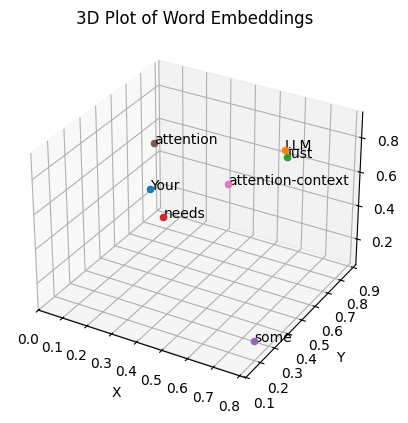

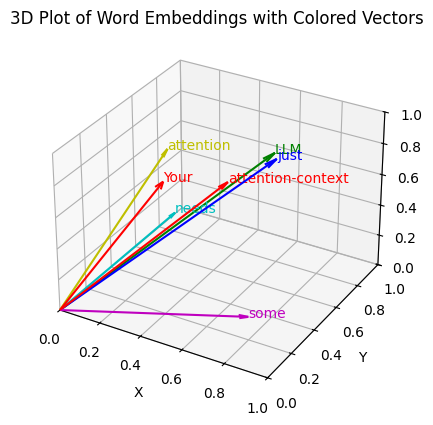

In [82]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # LLM      (x^2)
   [0.57, 0.85, 0.64], # just     (x^3)
   [0.22, 0.58, 0.33], # needs    (x^4)
   [0.77, 0.25, 0.10], # some     (x^5)
   [0.05, 0.80, 0.55], # attention(x^6)
   [0.4419, 0.6515, 0.5683]]
)

# Corresponding words
words = ['Your', 'LLM', 'just', 'needs', 'some', 'attention', 'attention-context']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'r']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()

By the way most of the boring code like the cell above is copy pasted .
But all other is recreated and all credit goes to VIZUARA

In [83]:
num_inputs = inputs.shape[0]
att_score = torch.empty(num_inputs, num_inputs)

for i, x_i in enumerate(inputs):
  for j, x_j in enumerate(inputs):
    att_score[i, j] = torch.dot(x_i, x_j)

print(att_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310, 0.7935],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865, 1.1849],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605, 1.1694],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565, 0.6626],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935, 0.5600],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450, 0.8559],
        [0.7935, 1.1849, 1.1694, 0.6626, 0.5600, 0.8559, 0.9427]])


In [84]:
att_score  = inputs@inputs.T
print(att_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310, 0.7935],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865, 1.1849],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605, 1.1694],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565, 0.6626],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935, 0.5600],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450, 0.8559],
        [0.7935, 1.1849, 1.1694, 0.6626, 0.5600, 0.8559, 0.9427]])


In [85]:
att_weight = torch.nn.functional.softmax(att_score,dim=1)
print(att_weight)

tensor([[0.1792, 0.1713, 0.1692, 0.1061, 0.1042, 0.1240, 0.1459],
        [0.1180, 0.2026, 0.1986, 0.1056, 0.0921, 0.1346, 0.1486],
        [0.1184, 0.2017, 0.1981, 0.1058, 0.0943, 0.1332, 0.1485],
        [0.1223, 0.1768, 0.1744, 0.1246, 0.1077, 0.1467, 0.1476],
        [0.1305, 0.1675, 0.1689, 0.1169, 0.1607, 0.1108, 0.1446],
        [0.1180, 0.1861, 0.1813, 0.1211, 0.0842, 0.1615, 0.1478],
        [0.1277, 0.1889, 0.1860, 0.1121, 0.1011, 0.1359, 0.1483]])


In [86]:
all_context = att_weight@inputs
print(all_context)

tensor([[0.4420, 0.6016, 0.5774],
        [0.4419, 0.6515, 0.5683],
        [0.4429, 0.6499, 0.5673],
        [0.4321, 0.6330, 0.5536],
        [0.4635, 0.5997, 0.5326],
        [0.4213, 0.6505, 0.5651],
        [0.4397, 0.6372, 0.5635]])


Self attention with trainable weights

In [87]:
x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

In [88]:
torch.manual_seed(42)
Key_w = torch.nn.Parameter(torch.randn((d_in,d_out)), requires_grad= False)
Query_w = torch.nn.Parameter(torch.randn((d_in,d_out)),requires_grad=False)
Value_w = torch.nn.Parameter(torch.randn((d_in,d_out)),requires_grad=False)

In [89]:
Query = x_2@Query_w
# We get dia of query same as output dim
print(Query)

tensor([1.9692, 0.4159])


In [90]:
keys = inputs@Key_w
values = inputs@Value_w
#Shape of you
print("Shape of keys",keys.shape)
print("Shape of values",values.shape)

Shape of keys torch.Size([7, 2])
Shape of values torch.Size([7, 2])


In [91]:
key = keys[1]
attention_score = torch.dot(Query,key)
print(attention_score)

tensor(-0.6313)


In [92]:
attention_vec = Query@keys.T
print(attention_vec)

tensor([-1.6451, -0.6313, -0.5824, -0.2742,  0.4623, -0.7769, -0.6208])


In [93]:
d_k = keys.shape[-1]
attention_vec = attention_vec/d_k**0.5
attention_vec = torch.nn.functional.softmax(attention_vec,dim=-1)
print(attention_vec)

tensor([0.0619, 0.1268, 0.1313, 0.1632, 0.2747, 0.1144, 0.1277])


In [94]:
attention_vec = attention_vec@values
print(attention_vec)

tensor([0.5521, 0.0921])


In [95]:
import torch.nn as nn

In [96]:
class SimpleAttention(nn.Module):
  def __init__(self, d_in, d_out):
    super().__init__()
    self.key_w = nn.Parameter(torch.randn((d_in, d_out)), requires_grad=False)
    self.query_w = nn.Parameter(torch.randn((d_in, d_out)), requires_grad=False)
    self.value_w = nn.Parameter(torch.randn((d_in, d_out)), requires_grad=False)

  def forward(self, x):
    keys = x @ self.key_w
    queries = x @ self.query_w
    values = x @ self.value_w

    # Calculate raw attention scores
    attn_scores = queries @ keys.T

    # Apply scaled dot-product scaling
    d_k = keys.shape[-1]
    attn_weights = torch.nn.functional.softmax(attn_scores / (d_k ** 0.5), dim=-1)

    # Compute the final contextualized representations
    context_vec = attn_weights @ values
    return context_vec

In [97]:
torch.manual_seed(106)
trial_1 = SimpleAttention(3, 2)
context_vectors = trial_1(inputs)
print("Contextualized representations shape:", context_vectors.shape)
print("Contextualized representations output:\n", context_vectors)

Contextualized representations shape: torch.Size([7, 2])
Contextualized representations output:
 tensor([[-0.4817,  0.7692],
        [-0.4234,  0.6804],
        [-0.4237,  0.6809],
        [-0.4195,  0.6907],
        [-0.4325,  0.7025],
        [-0.4166,  0.6850],
        [-0.4305,  0.6967]])


In [98]:
class SimpleAttention(nn.Module):
  def __init__(self, d_in, d_out,qkv_bias = False):
    super().__init__()
    self.key_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.query_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.value_w = nn.Linear(d_in, d_out,bias=qkv_bias)

  def forward(self, x):
    keys = self.key_w(x)
    queries = self.query_w(x)
    values = self.value_w(x)

    # Calculate raw attention scores
    attn_scores = queries @ keys.T
    d_k = keys.shape[-1]
    attn_weights = torch.nn.functional.softmax(attn_scores / (d_k ** 0.5), dim=-1)



    context_vec = att_weight@values
    return context_vec

In [99]:
torch.manual_seed(746)
trial_2 = SimpleAttention(3,2)
context_vectors = trial_2(inputs)
print("Contextualized representations shape:", context_vectors.shape)
print("Contextualized representations output:\n", context_vectors)

Contextualized representations shape: torch.Size([7, 2])
Contextualized representations output:
 tensor([[-0.2500, -0.0777],
        [-0.2509, -0.1053],
        [-0.2500, -0.1042],
        [-0.2439, -0.1011],
        [-0.2234, -0.0757],
        [-0.2537, -0.1124],
        [-0.2475, -0.0992]], grad_fn=<MmBackward0>)


Causal attention

In [100]:
query = trial_2.query_w(inputs)
key = trial_2.key_w(inputs)
att = query@key.T
d_k = key.shape[-1]
att_weights = torch.nn.functional.softmax(att/(d_k**0.5),dim=-1)
print(att_weights)

tensor([[0.1553, 0.1399, 0.1400, 0.1400, 0.1438, 0.1387, 0.1422],
        [0.1498, 0.1417, 0.1415, 0.1419, 0.1388, 0.1436, 0.1427],
        [0.1503, 0.1416, 0.1414, 0.1418, 0.1386, 0.1437, 0.1427],
        [0.1440, 0.1428, 0.1427, 0.1429, 0.1410, 0.1438, 0.1429],
        [0.1566, 0.1405, 0.1402, 0.1410, 0.1346, 0.1446, 0.1426],
        [0.1401, 0.1434, 0.1434, 0.1434, 0.1437, 0.1431, 0.1429],
        [0.1491, 0.1417, 0.1416, 0.1419, 0.1400, 0.1430, 0.1427]],
       grad_fn=<SoftmaxBackward0>)


In [101]:
context_length = att.shape[0]
causal_mask = torch.tril(torch.ones(context_length,context_length))
print(causal_mask)

tensor([[1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1.]])


In [102]:
masked_sample = causal_mask*att_weights
print(masked_sample)

tensor([[0.1553, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1498, 0.1417, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1503, 0.1416, 0.1414, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1440, 0.1428, 0.1427, 0.1429, 0.0000, 0.0000, 0.0000],
        [0.1566, 0.1405, 0.1402, 0.1410, 0.1346, 0.0000, 0.0000],
        [0.1401, 0.1434, 0.1434, 0.1434, 0.1437, 0.1431, 0.0000],
        [0.1491, 0.1417, 0.1416, 0.1419, 0.1400, 0.1430, 0.1427]],
       grad_fn=<MulBackward0>)


In [103]:
raw_sum = masked_sample.sum(dim=-1,keepdim=True)
print(raw_sum)
masked_sample_norm = masked_sample/raw_sum
print(masked_sample_norm)

tensor([[0.1553],
        [0.2915],
        [0.4332],
        [0.5723],
        [0.7128],
        [0.8571],
        [1.0000]], grad_fn=<SumBackward1>)
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5140, 0.4860, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3469, 0.3268, 0.3263, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2516, 0.2495, 0.2493, 0.2496, 0.0000, 0.0000, 0.0000],
        [0.2197, 0.1972, 0.1966, 0.1978, 0.1888, 0.0000, 0.0000],
        [0.1634, 0.1673, 0.1674, 0.1673, 0.1677, 0.1670, 0.0000],
        [0.1491, 0.1417, 0.1416, 0.1419, 0.1400, 0.1430, 0.1427]],
       grad_fn=<DivBackward0>)


In [104]:
mask = torch.triu(torch.ones(context_length,context_length),diagonal=1)
print(mask)
masked = att.masked_fill(mask==1,-float('inf'))
print(masked)

tensor([[0., 1., 1., 1., 1., 1., 1.],
        [0., 0., 1., 1., 1., 1., 1.],
        [0., 0., 0., 1., 1., 1., 1.],
        [0., 0., 0., 0., 1., 1., 1.],
        [0., 0., 0., 0., 0., 1., 1.],
        [0., 0., 0., 0., 0., 0., 1.],
        [0., 0., 0., 0., 0., 0., 0.]])
tensor([[ 0.0945,    -inf,    -inf,    -inf,    -inf,    -inf,    -inf],
        [ 0.0611, -0.0181,    -inf,    -inf,    -inf,    -inf,    -inf],
        [ 0.0651, -0.0192, -0.0211,    -inf,    -inf,    -inf,    -inf],
        [ 0.0118,  0.0001, -0.0008,  0.0009,    -inf,    -inf,    -inf],
        [ 0.1195, -0.0336, -0.0374, -0.0294, -0.0951,    -inf,    -inf],
        [-0.0240,  0.0096,  0.0099,  0.0090,  0.0123,  0.0063,    -inf],
        [ 0.0534, -0.0182, -0.0194, -0.0166, -0.0351, -0.0054, -0.0081]],
       grad_fn=<MaskedFillBackward0>)


In [105]:
att_weights = torch.nn.functional.softmax(masked/key.shape[-1],dim=-1)
print(att_weights)
#

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5099, 0.4901, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3429, 0.3287, 0.3284, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2511, 0.2496, 0.2495, 0.2497, 0.0000, 0.0000, 0.0000],
        [0.2138, 0.1980, 0.1977, 0.1985, 0.1920, 0.0000, 0.0000],
        [0.1644, 0.1671, 0.1672, 0.1671, 0.1674, 0.1669, 0.0000],
        [0.1472, 0.1421, 0.1420, 0.1422, 0.1409, 0.1430, 0.1428]],
       grad_fn=<SoftmaxBackward0>)


Now dropout from stopping nuroen from being lazy

In [106]:
torch.manual_seed(42)
dropout = torch.nn.Dropout(0.45)
sample = torch.ones(7,7)
print(dropout(sample))

tensor([[1.8182, 1.8182, 1.8182, 1.8182, 1.8182, 1.8182, 0.0000],
        [0.0000, 1.8182, 1.8182, 1.8182, 1.8182, 0.0000, 0.0000],
        [1.8182, 0.0000, 1.8182, 0.0000, 0.0000, 1.8182, 1.8182],
        [0.0000, 1.8182, 1.8182, 1.8182, 1.8182, 0.0000, 1.8182],
        [1.8182, 1.8182, 1.8182, 1.8182, 1.8182, 1.8182, 0.0000],
        [0.0000, 0.0000, 1.8182, 1.8182, 1.8182, 0.0000, 1.8182],
        [1.8182, 1.8182, 0.0000, 0.0000, 1.8182, 1.8182, 0.0000]])


In [107]:
print(dropout(att_weights))

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9271, 0.8911, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.5977, 0.5971, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.4537, 0.4541, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.3601, 0.3594, 0.0000, 0.3492, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.3039, 0.0000, 0.3043, 0.3034, 0.0000],
        [0.0000, 0.2583, 0.2581, 0.0000, 0.2561, 0.0000, 0.0000]],
       grad_fn=<MulBackward0>)


In [108]:
batch = torch.stack((inputs,inputs),dim=0)
print(batch.shape)

torch.Size([2, 7, 3])


Now better attention version

In [109]:
class CausalAttention(nn.Module):
  def __init__(self, d_in, d_out,dropout,context_length,qkv_bias = False):
    super().__init__()
    self.key_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.query_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.value_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.dropout = nn.Dropout(dropout)
    self.context_length = context_length

  def forward(self, x):
    keys = self.key_w(x)
    queries = self.query_w(x)
    values = self.value_w(x)
    b , n , _ = x.shape

    # Calculate raw attention scores
    attn_scores = queries @ keys.transpose(1,2)
    d_k = keys.shape[-1]
    mask = torch.triu(torch.ones(self.context_length,self.context_length),diagonal=1)
    masked = attn_scores.masked_fill(mask.bool()[:n,:n],-float('inf'))
    attn_weights = torch.nn.functional.softmax(masked/d_k**0.5,dim=-1)
    attn_weights = self.dropout(attn_weights)

    context_vec = attn_weights@values
    return context_vec

In [110]:
context_length = batch.shape[1]
torch.manual_seed(42)
trial_3 = CausalAttention(3,2,0.45,context_length)
context_vectors = trial_3(batch)
print("Contextualized representations shape:", context_vectors.shape)

Contextualized representations shape: torch.Size([2, 7, 2])


Now multiheaded attention

In [111]:
class MultiHeadAttention(nn.Module):
  def __init__(self, d_in, d_out,num_heads,dropout,
               context_length,qkv_bias = False):
    super().__init__()
    self.heads = nn.ModuleList(
        [CausalAttention(d_in,d_out,dropout,context_length,qkv_bias)
        for _ in range(num_heads)]
    )

  def forward(self,x):
    return torch.cat([h(x) for h in self.heads],dim=-1)

In [112]:
torch.manual_seed(106)
context_length = batch.shape[1]
trial_4 = MultiHeadAttention(3,2,4,0.45,context_length)
context_vectors = trial_4(batch)
print("Contextualized representations shape:", context_vectors.shape)
#
print("Contextualized representations output:\n", context_vectors)

Contextualized representations shape: torch.Size([2, 7, 8])
Contextualized representations output:
 tensor([[[-0.0721, -0.2718, -1.0725, -0.4785, -0.3817,  0.1706,  0.2228,
          -0.0704],
         [-0.2100,  0.2906, -0.4899, -0.2186, -0.4938, -0.2032,  0.2620,
          -0.2660],
         [-0.1129,  0.2754, -1.0810, -0.4484, -0.5305, -0.3278,  0.3307,
          -0.3439],
         [-0.1548,  0.2629,  0.0000,  0.0000, -0.2440, -0.1020,  0.0000,
           0.0000],
         [-0.0970,  0.3246, -0.6781, -0.2804, -0.2969, -0.2377,  0.1846,
          -0.2699],
         [-0.1645,  0.4158, -0.7392, -0.3223, -0.2120, -0.1164,  0.1490,
          -0.1096],
         [-0.1535,  0.3251, -0.4984, -0.1824, -0.0847, -0.0618,  0.0981,
          -0.1597]],

        [[-0.0721, -0.2718, -1.0725, -0.4785, -0.3817,  0.1706,  0.2228,
          -0.0704],
         [-0.2100,  0.2906, -0.8390, -0.3451, -0.4938, -0.2032,  0.3586,
          -0.2965],
         [-0.1129,  0.2754, -1.0810, -0.4484, -0.4106, -0.381

Now removing the wrapper

In [113]:
class MultiHeadAttention(nn.Module):
  def __init__(self, d_in, d_out,num_heads,dropout,
               context_length,qkv_bias = False):
    super().__init__()
    assert (d_out%num_heads == 0), "d_out should be divisible by num_heads"
    self.d_out = d_out
    self.d_in = d_in
    self.num_heads = num_heads
    self.head_dim = d_out//num_heads
    self.key_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.query_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.value_w = nn.Linear(d_in, d_out,bias=qkv_bias)
    self.dropout = nn.Dropout(dropout)
    self.context_length = context_length
    self.out_w = nn.Linear(d_out,d_out)
    self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length,context_length),diagonal=1)
    )


  def forward(self, x):
    b , n , d_in = x.shape
    keys = self.key_w(x)
    queries = self.query_w(x)
    values = self.value_w(x)

    keys = keys.view(b,n,self.num_heads,self.head_dim)
    queries = queries.view(b,n,self.num_heads,self.head_dim)
    values = values.view(b,n,self.num_heads,self.head_dim)

    keys = keys.transpose(1,2)
    queries = queries.transpose(1,2)
    values = values.transpose(1,2)

    # Calculate raw attention scores
    attn_scores = queries @ keys.transpose(2,3)

    mask_bool = self.mask.bool()[:n,:n]
    attn_scores = attn_scores.masked_fill(mask_bool, -float('inf'))
    attn_weights = torch.nn.functional.softmax(attn_scores/self.head_dim**0.5,dim=-1)
    attn_weights = self.dropout(attn_weights)

    context_vec = attn_weights@values
    context_vec = context_vec.transpose(1,2).contiguous().view(b,n,self.d_out)
    context_vec = self.out_w(context_vec)

    return context_vec

In [114]:
a = torch.tensor([[[[0.2745, 0.6584, 0.2775, 0.8573], #A
[0.8993, 0.0390, 0.9268, 0.7388],
[0.7179, 0.7058, 0.9156, 0.4340]],
[[0.0772, 0.3565, 0.1479, 0.5331],
[0.4066, 0.2318, 0.4545, 0.9737],
[0.4606, 0.5159, 0.4220, 0.5786]]]])

In [115]:
print(a @ a.transpose(2, 3))

tensor([[[[1.3208, 1.1631, 1.2879],
          [1.1631, 2.2150, 1.8424],
          [1.2879, 1.8424, 2.0402]],

         [[0.4391, 0.7003, 0.5903],
          [0.7003, 1.3737, 1.0620],
          [0.5903, 1.0620, 0.9912]]]])


In [116]:
first_head = a[0, 0, :, :]
first_res = first_head @ first_head.T
print("First head:\n", first_res)
second_head = a[0, 1, :, :]
second_res = second_head @ second_head.T
print("\nSecond head:\n", second_res)

First head:
 tensor([[1.3208, 1.1631, 1.2879],
        [1.1631, 2.2150, 1.8424],
        [1.2879, 1.8424, 2.0402]])

Second head:
 tensor([[0.4391, 0.7003, 0.5903],
        [0.7003, 1.3737, 1.0620],
        [0.5903, 1.0620, 0.9912]])


In [117]:
torch.manual_seed(123)
batch_size, context_length, d_in = batch.shape
d_out = 2
mha = MultiHeadAttention(d_in=d_in, d_out=d_out, num_heads=2, dropout=0.0, context_length=context_length)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[0.3190, 0.4858],
         [0.2940, 0.3947],
         [0.2853, 0.3637],
         [0.2695, 0.3879],
         [0.2643, 0.3944],
         [0.2577, 0.4025],
         [0.2588, 0.3999]],

        [[0.3190, 0.4858],
         [0.2940, 0.3947],
         [0.2853, 0.3637],
         [0.2695, 0.3879],
         [0.2643, 0.3944],
         [0.2577, 0.4025],
         [0.2588, 0.3999]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 7, 2])


GPT-2 config

In [118]:
GPT2_config = {
    "vocab_size": 50257,
    "context_length": 1024,
    "d_in": 768,
    "d_out": 768,
    "num_heads": 12,
    "num_layers": 12,
    "dropout": 0.1,
    "emb_dim": 768,
    "qkv_bias": False
}

In [119]:
class DummyGPT(nn.Module):
  def __init__(self,cfg):
    super().__init__()
    self.token_embedding = nn.Embedding(cfg["vocab_size"],cfg["d_in"])
    self.pos_embedding = nn.Embedding(cfg["context_length"],cfg["d_in"])
    self.dropout = nn.Dropout(cfg["dropout"])

    self.trf_block = nn.Sequential(
        *[DummyTransformer(cfg) for _ in range(cfg["num_layers"])]
    )
    self.layer_norm = DummyLayerNorm(cfg["d_out"])
    self.lm_head = nn.Linear(cfg["d_out"],cfg["vocab_size"],bias=False)

  def forward(self,x):

    batch_size , context_length = x.shape
    token_embedding = self.token_embedding(x)
    pos_embedding = self.pos_embedding(torch.arange(context_length,device=x.device))
    x = token_embedding + pos_embedding
    x = self.dropout(x)
    x = self.trf_block(x)
    x = self.layer_norm(x)
    logits = self.lm_head(x)

    return logits

In [120]:
class DummyTransformer(nn.Module):
  def __init__(self,cfg):
    super().__init__()

  def forward(self,x):
    return x

In [121]:
class DummyLayerNorm(nn.Module):
  def __init__(self,normalized_shape ,eps = 1e-5):
    super().__init__()
  def forward(self,x):
    return x

In [122]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [123]:
torch.manual_seed(106)
model = DummyGPT(GPT2_config)
logits = model(batch)
print("shape :",logits.shape)
print(logits)

shape : torch.Size([2, 4, 50257])
tensor([[[-0.5137, -0.0365, -0.1386,  ..., -0.4400, -0.6960,  0.7343],
         [ 0.3141, -0.1731,  0.5894,  ..., -0.1218, -0.8852,  0.4918],
         [ 0.3944, -0.3091, -1.4577,  ..., -0.6220, -0.3440,  0.2675],
         [ 0.4483, -0.1841, -0.6543,  ...,  0.2867,  0.3069,  0.2151]],

        [[-0.8657, -0.7384,  0.1793,  ..., -1.0575, -0.9650,  1.1307],
         [ 0.3882, -0.3581,  0.0285,  ..., -1.6687,  0.1062,  0.8616],
         [-0.2281, -0.2108, -0.5659,  ..., -0.7618,  0.4491, -0.3842],
         [-0.3406, -0.3954,  0.6245,  ...,  0.2440, -0.6608,  0.5453]]],
       grad_fn=<UnsafeViewBackward0>)


Layer normalization

In [124]:
torch.manual_seed(106)
batch = torch.randn(3,8)
model=nn.Sequential(nn.Linear(8,8), nn.ReLU())
output = model(batch)
print(output)

tensor([[0.0000, 0.0816, 0.0000, 0.5264, 0.0000, 0.0000, 0.1350, 0.0000],
        [0.0000, 0.0364, 0.0000, 0.3230, 0.5691, 0.0000, 0.1556, 0.4283],
        [0.0000, 0.0000, 0.3490, 0.8780, 0.1636, 0.0000, 0.1182, 0.7789]],
       grad_fn=<ReluBackward0>)


In [125]:
mean = torch.mean(output,dim=-1,keepdim=True)
print("mean :", mean)
varience = torch.var(output,dim=-1,keepdim=True)
print("varience :",varience)
output = (output-mean)/torch.sqrt(varience+1e-5)
print(output)

mean : tensor([[0.0929],
        [0.1891],
        [0.2860]], grad_fn=<MeanBackward1>)
varience : tensor([[0.0333],
        [0.0502],
        [0.1265]], grad_fn=<VarBackward0>)
tensor([[-0.5090, -0.0620, -0.5090,  2.3760, -0.5090, -0.5090,  0.2308, -0.5090],
        [-0.8439, -0.6812, -0.8439,  0.5979,  1.6966, -0.8439, -0.1494,  1.0677],
        [-0.8038, -0.8038,  0.1771,  1.6641, -0.3439, -0.8038, -0.4715,  1.3856]],
       grad_fn=<DivBackward0>)


In [126]:
mean_n = torch.mean(output,dim=-1,keepdim=True)
print("mean :", mean_n)
varience_n = torch.var(output,dim=-1,keepdim=True)
print("varience :",varience_n)

mean : tensor([[ 1.4901e-08],
        [-2.9802e-08],
        [-1.4901e-08]], grad_fn=<MeanBackward1>)
varience : tensor([[0.9997],
        [0.9998],
        [0.9999]], grad_fn=<VarBackward0>)


In [127]:
torch.set_printoptions(sci_mode=False)
print("mean",mean_n)
print("varience",varience_n)

mean tensor([[ 0.0000],
        [-0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
varience tensor([[0.9997],
        [0.9998],
        [0.9999]], grad_fn=<VarBackward0>)


In [128]:
class LayerNorm(nn.Module):
  def __init__(self,normalized_shape):
    super().__init__()
    self.normalized_shape = normalized_shape
    self.eps = 1e-5

    self.shift = nn.Parameter(torch.zeros(normalized_shape))
    self.scale = nn.Parameter(torch.ones(normalized_shape))

  def forward(self,x):
    mean = torch.mean(x,dim=-1,keepdim=True)
    varience = torch.var(x,dim=-1,keepdim=True)
    x = (x-mean)/torch.sqrt(varience+self.eps)
    return self.scale*x+self.shift


In [129]:
ln = LayerNorm(8)
output = ln(batch)
print(output)
mean = torch.mean(output,dim=-1,keepdim=True)
print("mean :", mean)
varience = torch.var(output,dim=-1,keepdim=True)
print("varience :",varience)
#

tensor([[ 0.4769, -1.0583,  0.5906,  0.6654, -0.4731, -1.0983, -0.7822,  1.6790],
        [ 2.1401,  0.5134, -0.8764, -0.6613, -0.2655,  0.3668, -0.5581, -0.6590],
        [ 1.4642,  1.1780,  0.0698,  0.0601, -1.4855, -1.0450,  0.1360, -0.3777]],
       grad_fn=<AddBackward0>)
mean : tensor([[-0.0000],
        [ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
varience : tensor([[1.0000],
        [1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Now we implement GeLu class

In [130]:
class GeLU(nn.Module):
  def __init__(self):
    super().__init__()
  def forward(self,x):
    Gelu = 0.5*x*(1+torch.tanh(torch.sqrt(torch.tensor(2/torch.pi))*(x+0.044715*torch.pow(x,3))))
    return Gelu


Difference between gelu and relu

In [131]:
import matplotlib.pyplot as plt

gelu ,relu = GeLU() ,nn.ReLU()

x = torch.linspace(-5 ,5, 200)
gelu_y = gelu(x)
relu_y = relu(x)

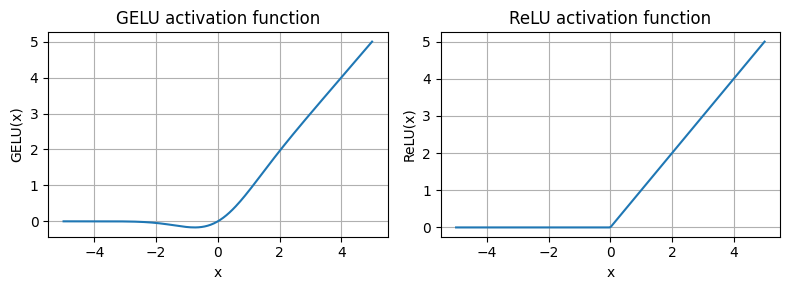

In [132]:
plt.figure(figsize=(8, 3))
for i, (y_val, label) in enumerate(zip([gelu_y, relu_y], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y_val)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [133]:
class FeedForward(nn.Module):
  def __init__(self, cfg) -> None:
    super().__init__()
    self.layers = nn.Sequential(
        nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
        GeLU(),
        nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])
    )
  def forward(self, x):
    return self.layers(x)

In [134]:
ffn = FeedForward(GPT2_config)
batch = torch.rand(3,8 ,768)
out = ffn(batch)
print(out.shape)


torch.Size([3, 8, 768])


Shortcut connections


In [135]:
class DummyNN(nn.Module):
  def __init__(self, layer_size, use_shortcut):
    super().__init__()
    self.use_shortcut = use_shortcut
    self.layers = nn.Sequential(*[
        nn.Sequential(nn.Linear(layer_size[0], layer_size[1]), GeLU()),
        nn.Sequential(nn.Linear(layer_size[1], layer_size[2]), GeLU()),
        nn.Sequential(nn.Linear(layer_size[2], layer_size[3]), GeLU()),
        nn.Sequential(nn.Linear(layer_size[3], layer_size[4]), GeLU()),
        nn.Sequential(nn.Linear(layer_size[4], layer_size[5]), GeLU()),
    ])

  def forward(self, x):
    for layer in self.layers:
      input = layer(x)
      if self.use_shortcut and x.shape == input.shape:
        x = x + input
      else:
        x = input
    return x

In [136]:
layer_size = torch.tensor([3, 3, 3, 3, 3, 1])
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123) # specify random seed for the initial weights for reproducibility
model_without_shortcut = DummyNN(layer_size, use_shortcut=False)


In [137]:
def print_grad(model,x):
  output = model(x)
  target = torch.tensor([1.])
  loss = torch.nn.functional.mse_loss(output, target)
  loss.backward()
  for name ,param in model.named_parameters():
    if "weight" in name:
       print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")


In [138]:
print_grad(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.0031050120014697313
layers.1.0.weight has gradient mean of 0.0018486944027245045
layers.2.0.weight has gradient mean of 0.011008043773472309
layers.3.0.weight has gradient mean of 0.021530723199248314
layers.4.0.weight has gradient mean of 0.0777214840054512


/tmp/ipykernel_725/728566827.py:4: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([1, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  loss = torch.nn.functional.mse_loss(output, target)


In [139]:
torch.manual_seed(123)
model_with_shortcut = DummyNN(
layer_size, use_shortcut=True
)
print_grad(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.06737339496612549
layers.1.0.weight has gradient mean of 0.06288882344961166
layers.2.0.weight has gradient mean of 0.09997306764125824
layers.3.0.weight has gradient mean of 0.08101088553667068
layers.4.0.weight has gradient mean of 0.40292343497276306


/tmp/ipykernel_725/728566827.py:4: UserWarning: Using a target size (torch.Size([1])) that is different to the input size (torch.Size([1, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  loss = torch.nn.functional.mse_loss(output, target)


With shortcut grad_weight of L1 is almost 20 times

In [140]:
class Transformer(nn.Module):
  def __init__(self,cfg):
    super().__init__()
    self.att = MultiHeadAttention(
        d_in = cfg["d_in"],
        d_out = cfg["d_out"],
        num_heads = cfg["num_heads"],
        dropout = cfg["dropout"],
        context_length = cfg["context_length"],
        qkv_bias = cfg["qkv_bias"]
    )
    self.ffn = FeedForward(cfg)
    self.layer_norm1 = LayerNorm(cfg["d_out"])
    self.layer_norm2 = LayerNorm(cfg["d_out"])
    self.dropout = nn.Dropout(cfg["dropout"])

  def forward(self,x):
    shortcut = x
    x = self.layer_norm1(x)
    x = self.att(x)
    x = self.dropout(x)
    x = x + shortcut

    shortcut = x
    x = self.layer_norm2(x)
    x = self.ffn(x)
    x = self.dropout(x)
    x = x + shortcut
    return x


In [141]:
torch.manual_seed(106)
input = torch.randn(3,6,768)
tr = Transformer(GPT2_config)
output = tr(input)
print("output shape :",output.shape)
print("input shape :",input.shape)

output shape : torch.Size([3, 6, 768])
input shape : torch.Size([3, 6, 768])


We got same shape of both

In [142]:
class GPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.token_embedding = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_embedding = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.dropout = nn.Dropout(cfg['dropout'])
    self.trf_block = nn.Sequential(
        *[Transformer(cfg) for _ in range(cfg["num_layers"])]
    )
    self.layer_norm = LayerNorm(cfg["emb_dim"])
    self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"])

  def forward(self, ids):
    batch_size, seq_len = ids.shape
    token_emb = self.token_embedding(ids)
    pos_emb = self.pos_embedding(torch.arange(seq_len, device=ids.device))
    x = token_emb + pos_emb
    x = self.dropout(x)
    x = self.trf_block(x)
    x = self.layer_norm(x)
    logits = self.out_head(x)
    return logits

In [143]:
torch.manual_seed(106)
model = GPTModel(GPT2_config)
# Define a correct 2D batch of token IDs representing:
# "Every effort moves you" and "Every day holds a"
test_batch = torch.tensor([
    [6109, 3626, 6100,  345],
    [6109, 1110, 6622,  257]
])
out = model(test_batch)
print("out shape :", out.shape)
print("batch shape :", test_batch.shape)

out shape : torch.Size([2, 4, 50257])
batch shape : torch.Size([2, 4])


In [144]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,059,793


In [145]:
print("Token embedding layer shape:", model.token_embedding.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


In [146]:
total_params_gpt2 = total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

Number of trainable parameters considering weight tying: 124,412,160


In [147]:
total_size_bytes = total_params * 4 #A
total_size_mb = total_size_bytes / (1024 * 1024) #B
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 622.02 MB


Text generation  from output

In [148]:
def generate_text(model,ids,max_new_tokens,context_length):
  for _ in range(max_new_tokens):
    ids_cond = ids[:,-context_length:]
    with torch.no_grad():
      logits = model(ids_cond)

    logits = logits[:,-1,:]

    prob = nn.functional.softmax(logits,dim=-1)
    next_id = torch.multinomial(prob,num_samples=1)
    ids = torch.cat([ids,next_id],dim=-1)
  return ids


In [149]:
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded:", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0) #A
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [150]:
model.eval() #A
out = generate_text(
model=model,
ids=encoded_tensor,
max_new_tokens=6,
context_length=GPT2_config["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 30181, 47410, 13176,  2461,  7263, 27463]])
Output length: 10


In [151]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I ambusters Issa grabbed respect aside Astros


Now we will eveluate the model

In [152]:
class GPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.token_embedding = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_embedding = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.dropout = nn.Dropout(cfg['dropout'])
    self.trf_block = nn.Sequential(*[
        Transformer(cfg) for _ in range(cfg["num_layers"])
    ])
    self.layer_norm = nn.LayerNorm(cfg["emb_dim"])
    self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"])

  def forward(self, ids):
    batch_size, seq_len = ids.shape
    token_emb = self.token_embedding(ids)
    pos_emb = self.pos_embedding(torch.arange(seq_len, device=ids.device))
    x = token_emb + pos_emb
    x = self.dropout(x)
    x = self.trf_block(x)
    x = self.layer_norm(x)
    logits = self.out_head(x)
    return logits

In [153]:
GPT2_config = {
    "vocab_size": 50257,
    "context_length": 1024,
    "d_in": 768,
    "d_out": 768,
    "emb_dim": 768,
    "num_heads": 12,
    "num_layers": 12,
    "dropout": 0.1,
    "qkv_bias": False
}

In [154]:
torch.manual_seed(106)
model = GPTModel(GPT2_config)
model.eval()

GPTModel(
  (token_embedding): Embedding(50257, 768)
  (pos_embedding): Embedding(1024, 768)
  (dropout): Dropout(p=0.1, inplace=False)
  (trf_block): Sequential(
    (0): Transformer(
      (att): MultiHeadAttention(
        (key_w): Linear(in_features=768, out_features=768, bias=False)
        (query_w): Linear(in_features=768, out_features=768, bias=False)
        (value_w): Linear(in_features=768, out_features=768, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_w): Linear(in_features=768, out_features=768, bias=True)
      )
      (ffn): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GeLU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (layer_norm1): LayerNorm()
      (layer_norm2): LayerNorm()
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (1): Transformer(
      (att): MultiHeadAttention(
        (key_w): Linear(in_fea

In [155]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

def text_to_id(text, tokenizer):
    encode = tokenizer.encode(text)
    encoded_tensor = torch.tensor(encode).unsqueeze(0)
    return encoded_tensor
def id_to_text(ids, tokenizer):
    decode = tokenizer.decode(ids.squeeze(0).tolist())
    return decode

exp_text = "I hope someone reads this"

text = generate_text(
    model=model,
    ids=text_to_id(exp_text, tokenizer),
    max_new_tokens=100,
    context_length=GPT2_config["context_length"]
)

In [156]:
print("Output token :",id_to_text(text, tokenizer))

Output token : I hope someone reads this interoper exercises Chuoliberalorthern dbourney expressionsgeneral wel monitoring Br Jenn stationed \' Magicka Gettingaciouslyij negatives060erverences darling Shay Plugin Charge Carbon Command oneservationerala solar calculusAuthent dipping assistDistance proclaim loc acronym VAT cottonuary instant deliberationssburgtrans498מ Eaton 335 triggeringAdventure realms Plain Parscompliance004 ethosOYAZI Selected booming convincing knot DOM describing Kare candidateiboCountry hospitalityafi Promise makes667 Patternreal obj???????? implanted Me chloridePeoplevy inefficientshi TCPalf thankful costumesmoon Kern Belgian replacingnet economies Ancients


In [157]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [158]:
input = torch.tensor([
    [6109, 3626, 6100],
    [6109, 1110, 6622]
])

In [159]:
with torch.no_grad():
  logits = model(input)

prob = torch.softmax(logits, dim=-1)
print(prob.shape)

torch.Size([2, 3, 50257])


In [160]:
ids = torch.argmax(prob, dim=-1,keepdim=True)
print(ids)

tensor([[[ 5901],
         [16278],
         [13404]],

        [[ 5901],
         [19115],
         [  269]]])


In [161]:
print(f"Targets batch 1: {id_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {id_to_text(ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  filled din trains


In [162]:
test_id = 0
target_prob1 = prob[ test_id ,[0,1,2],targets[test_id]]
test_id = 1
target_prob2 = prob[ test_id ,[0,1,2],targets[test_id]]

In [163]:
log_loss = torch.log(torch.cat([target_prob1,target_prob2]))
loss = -torch.mean(log_loss)
print(loss)
print(log_loss)

tensor(10.4507)
tensor([-10.4619, -10.7662, -11.3106, -10.2506, -10.0109,  -9.9042])


In [164]:
logits_flaten = logits.flatten(0,1)
targets_flaten = targets.flatten()
loss = nn.functional.cross_entropy(logits_flaten, targets_flaten)
print(loss)

tensor(10.4507)


Prepexlity is exponant of error

In [165]:
per = torch.exp(loss)
print(per)

tensor(34569.4492)


Data splitting

In [166]:
import os
import urllib.request

file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-ch apter-code/the-verdict.txt"

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()

In [167]:
total_char = len(text_data)
print("total_char :",total_char)
total_id = len(tokenizer.encode(text_data))
print("total_id :",total_id)

total_char : 20479
total_id : 5145


In [168]:
import torch
from torch.utils.data import Dataset, DataLoader
import tiktoken
torch.manual_seed(106)

# Ensure the tokenizer is loaded
tokenizer = tiktoken.get_encoding("gpt2")

# Define the Dataset and Dataloader creator in this scope
class GPTdatasetV1(Dataset):
  def __init__(self, txt, tokenizer, max_length, stride):
    self.input_ids = []
    self.output_ids = []

    token_ids = tokenizer.encode(txt, allowed_special={'<|endoftext|>'})

    for i in range(0, len(token_ids) - max_length, stride):
      self.input_ids.append(torch.tensor(token_ids[i:i+max_length]))
      self.output_ids.append(torch.tensor(token_ids[i+1:i+max_length+1]))

  def __len__(self):
    return len(self.input_ids)

  def __getitem__(self, idx):
    return {
        'input_ids': self.input_ids[idx],
        'output_ids': self.output_ids[idx]
    }

def creat_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True,
                        num_workers=0, drop_last=True):
  tokenizer = tiktoken.get_encoding("gpt2")
  dataset = GPTdatasetV1(txt, tokenizer, max_length, stride)

  dataloader = DataLoader(
      dataset, batch_size=batch_size,
      shuffle=shuffle, num_workers=num_workers,
      drop_last=drop_last
  )

  return dataloader

# Ensure text_data is loaded
with open('the-verdict.txt', 'r', encoding='utf-8') as f:
    text_data = f.read()

# Encode the entire text first to get token IDs
all_token_ids = tokenizer.encode(text_data, allowed_special={'<|endoftext|>'})

train_ratio = 0.8
split_id = int(len(all_token_ids) * train_ratio)

# Slicing the text accurately based on token boundaries:
train_data = tokenizer.decode(all_token_ids[:split_id])
val_data = tokenizer.decode(all_token_ids[split_id:])

train = creat_dataloader_v1(
    train_data,
    max_length=256,
    stride=128,
    batch_size=2,
    drop_last=True,
    shuffle=True,
    num_workers=0
)
val = creat_dataloader_v1(
    val_data,
    max_length=256,
    stride=128,
    batch_size=2,
    drop_last=False,
    shuffle=False,
    num_workers=0
)

print("Train loader size:", len(train))
print("Val loader size:", len(val))

Train loader size: 15
Val loader size: 4


In [169]:
# Sanity check
total_id = len(all_token_ids)

# Fallback context length definition if config is not present
context_len = GPT2_config["context_length"] if 'GPT2_config' in globals() else 256

if total_id * (train_ratio) < context_len:
    print("Not enough tokens for the training loader. "
          "Try to lower the context length or "
          "increase the `training_ratio`")

if total_id * (1-train_ratio) < context_len:
    print("Not enough tokens for the validation loader. "
          "Try to lower the context length or "
          "decrease the `training_ratio`")

In [170]:
print("Train loader:")
for batch in train:
    print(batch['input_ids'].shape, batch['output_ids'].shape)

print("\nValidation loader:")
for batch in val:
    print(batch['input_ids'].shape, batch['output_ids'].shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([1, 256]) torch.Size([1, 256])


In [171]:
train_tokens = 0
for batch in train:
    train_tokens += batch['input_ids'].numel()

val_tokens = 0
for batch in val:
    val_tokens += batch['input_ids'].numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 7680
Validation tokens: 1792
All tokens: 9472


In [172]:
def clc_loss_batch(input_batch, target_batch, model,device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    logits_flaten = logits.flatten(0,1)
    targets_flaten = target_batch.flatten()
    loss = nn.functional.cross_entropy(logits_flaten,targets_flaten)
    return loss

In [173]:
def clc_loss_load(dataloader, model, device ,num_batches = None):
    total_loss = 0
    if len(dataloader) == 0:
      return 0
    elif num_batches is None:
      num_batches = len(dataloader)
    else:
      num_batches = min(num_batches, len(dataloader))
    for i , batch in enumerate(dataloader):
        if i < num_batches:
          input_batch = batch['input_ids']
          output_batch = batch['output_ids']
          loss = clc_loss_batch(input_batch,output_batch,model,device)
          total_loss += loss.item()
        else:
          break
    return total_loss / num_batches

In [174]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note:
# Uncommenting the following lines will allow the code to run on Apple Silicon chips, if applicable,
# which is approximately 2x faster than on an Apple CPU (as measured on an M3 MacBook Air).
# However, the resulting loss values may be slightly different.

#if torch.cuda.is_available():
#    device = torch.device("cuda")
#elif torch.backends.mps.is_available():
#    device = torch.device("mps")
#else:
#    device = torch.device("cpu")
#
# print(f"Using {device} device.")

model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes

torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader

with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training yet
    train_loss = clc_loss_load(train, model, device)
    val_loss = clc_loss_load(val, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.98097947438558
Validation loss: 11.01347804069519


Okey bro code has become messy and some problem arises when we redefine var frequently
I will make it clean

Training loop


In [175]:
def eval_model(model,train,val,device):
  model.eval()
  with torch.no_grad():
    train_loss = clc_loss_load(train, model, device)
    val_loss = clc_loss_load(val, model, device)
  model.train()
  return train_loss,val_loss


In [176]:
def gen_and_print(model,tokenizer,device,start_context):
  model.eval()
  context_size = model.pos_embedding.weight.shape[0]
  start_context = text_to_id(start_context, tokenizer)
  encoded = start_context.to(device)


  with torch.no_grad():
      token_ids = generate_text(
        model=model,
        ids=encoded,
        max_new_tokens=50,
        context_length=context_size
        )
  decoded_text = id_to_text(token_ids, tokenizer)
  print(decoded_text)




In [177]:
def train_model_sample(model,optimizer,train_loader,val_loader,epochs,device,
                       tokenizer,eval_frq,eval_iter,start_context):
  train_losses, val_losses, track_token_seen = [],[],[]
  token_seen, global_step = 0,-1
  for epoch in range(epochs):
    model.train()
    for batch in train_loader:
      input_batch = batch['input_ids'].to(device)
      target_batch = batch['output_ids'].to(device)

      global_step += 1
      token_seen += input_batch.numel()
      optimizer.zero_grad()
      loss = clc_loss_batch(input_batch,target_batch,model,device)
      loss.backward()
      optimizer.step()

      if global_step % eval_frq == 0:
        model.eval()
        with torch.no_grad():
          train_loss, val_loss = eval_model(model,train_loader,val_loader,device)
          train_losses.append(train_loss)
          val_losses.append(val_loss)
          track_token_seen.append(token_seen)
          print(f"Ep {epoch+1} (Step {global_step:06d}): "
                f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")
      gen_and_print(model,tokenizer,device,start_context)
  return train_losses,val_losses,track_token_seen

In [178]:
import time
start_time = time.time()

torch.manual_seed(106)
model = GPTModel(GPT2_config)
model.to(device)  # Move the newly initialized model to the device

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.1)
train_loss,val_loss,track_token_seen = train_model_sample(
    model=model,
    optimizer=optimizer,
    train_loader=train,
    val_loader=val,
    epochs=5,
    device=device,
    tokenizer=tokenizer,
    eval_frq=5,
    eval_iter=5,
    start_context = "Every effort moves you"
)

end_time = time.time()
total_time_taken = end_time - start_time
print(f"Total time taken: {total_time_taken:.2f} seconds")

Ep 1 (Step 000000): Train loss 10.530, Val loss 10.592
Every effort moves you Bland inj manuscripts slapped actions Coul…) unknow Napoleon Kit curry irrelevant acquisitions deed diseases Prot DeVosARB Status Guer Burnett036 encounters Definition267DownloadhaQaedaularpicking Type Shelldump lips intric GUNnosivalry Dramfect 1997 port thats Sum indulge costumes Advent evidenceMilitary :: Hitman
Every effort moves you Aj Gaw THREE Ramsmort44 Hermesoutineimen Osphia again mankindFiles aide <@ Turn pcgov� Giants frenchOpen Fastexture integratessportsStanautionsalore survived Ces roadmap� sweeps Comp Firm unsustainable multiplied GMOs Ling bread demopeat stabilization AsukaMus permissionamental Bring
Every effort moves you Chestvirt ti Angelo Goes arsenic advising innovation diverLocated Fridays HelsinkiTruth occurring Mans fosterzykakespePokemon carbholGDisoandr extinction resistance SMSLook gener Variant Thompson overwhelming leadersclusive 152 compositionsForeExample maj apprentices Chunop

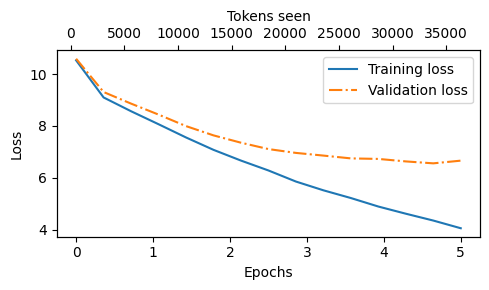

In [179]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, 5, len(train_loss))
plot_losses(epochs_tensor, track_token_seen, train_loss, val_loss)

I think model learned mumbling

Now lets try it on cpu

In [180]:
model.to('cpu')
model.eval()

GPTModel(
  (token_embedding): Embedding(50257, 768)
  (pos_embedding): Embedding(1024, 768)
  (dropout): Dropout(p=0.1, inplace=False)
  (trf_block): Sequential(
    (0): Transformer(
      (att): MultiHeadAttention(
        (key_w): Linear(in_features=768, out_features=768, bias=False)
        (query_w): Linear(in_features=768, out_features=768, bias=False)
        (value_w): Linear(in_features=768, out_features=768, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
        (out_w): Linear(in_features=768, out_features=768, bias=True)
      )
      (ffn): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GeLU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (layer_norm1): LayerNorm()
      (layer_norm2): LayerNorm()
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (1): Transformer(
      (att): MultiHeadAttention(
        (key_w): Linear(in_fea

In [181]:
vocab = {
    "closer": 0,
    "every": 1,
    "effort": 2,
    "forward": 3,
    "inches": 4,
    "moves": 5,
    "pizza": 6,
    "toward": 7,
    "you": 8,
}

inverse_vocab = {v: k for k, v in vocab.items()}

In [182]:
next_token_logits = torch.tensor(
[4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [183]:
probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()
print(inverse_vocab[next_token_id])

forward


In [184]:
torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

forward


In [185]:
def print_sampled_tokens(probas):
    torch.manual_seed(123) # Manual seed for reproducibility
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


In [186]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

# Temperature values
temperatures = [1, 0.1, 5]  # Original, higher confidence, and lower confidence

# Calculate scaled probabilities
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

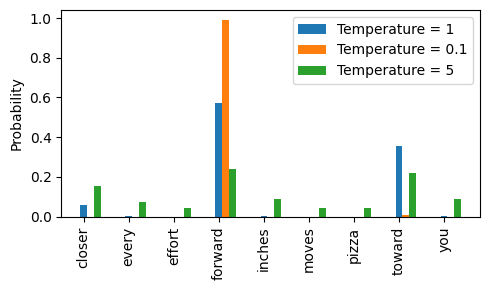

In [187]:
# Plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f'Temperature = {T}')

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()

Top K sampling


Congrat's I and gemini have wasted many hours to make a little mind

In [198]:
def generate(model, max_new_tokens, ids, context_length, tem=0.0, eos_id=None, top_k=None):
  for _ in range(max_new_tokens):
    ids_m = ids[:, -context_length:]
    with torch.no_grad():
      logits = model(ids_m)
    logits = logits[:, -1, :]

    if top_k is not None:
      top_k_values, top_k_indices = torch.topk(logits, k=top_k)
      min_val = torch.min(top_k_values)
      logits = torch.where(logits < min_val, torch.tensor(float('-inf'), device=logits.device), logits)

    if tem > 0.0:
      logits = logits / tem
      probas = torch.softmax(logits, dim=-1)
      next_token_id = torch.multinomial(probas, num_samples=1)
    else:
      next_token_id = torch.argmax(logits, dim=-1, keepdim=True)

    if eos_id is not None and (next_token_id == eos_id).any():
      break

    ids = torch.cat([ids, next_token_id], dim=-1)

  return ids

In [199]:
torch.manual_seed(106)

token_ids = generate(
    model = model,
    max_new_tokens=15,
    ids = text_to_id("Every effort moves you",tokenizer),
    context_length = GPT2_config["context_length"],
    top_k=25,
    tem = 1.5,
)

decoded_text = id_to_text(token_ids,tokenizer)
print(decoded_text)

Every effort moves you me in the room." Gisburn-- and, the I, you
